***LAB 5***

Vacuum robot using **Q-learning**.
Same grid and hidden-model environment as Lab 4: the robot does not know T or R. In Lab 4 it only
explored at random and collected samples `(s, a, r, s')`. Here a `QLearningAgent` turns those samples
into Q-values and a policy, using ε-greedy exploration. The code lives in `vacuum_rl.py` so the
notebook, the `train-qlearning` skill and the hooks all share one implementation.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from vacuum_rl import (MOVES, GRID, START, CHARGER, TRAP, VacuumEnv, QLearningAgent,
                       show_grid, train, evaluate, policy_grid, run_qlearning,
                       value_iteration_reference, outcome_of)

# Lab 5 hyperparameters (see docs/DESIGN_DECISIONS.md)
LIVING_REWARD = -0.04
GAMMA = 0.9
ALPHA = 0.1
EPSILON_START, EPSILON_END = 1.0, 0.05
N_EPISODES = 5000
SEED = 0

show_grid(GRID, "LAB 5 GRID")

LAB 5 GRID
     0S   0    0    0 
     0    X    0    0 
     0    0    0    0 
     0   -1    0   10 



## The Q-learning update

After every `env.step()` the agent gets one sample and blends it into its estimate (slides RL-L2):

sample = r + γ max<sub>a'</sub> Q(s', a')   (0 if s' is terminal)

Q(s, a) ← (1 − α) Q(s, a) + α · sample

The agent only uses `reset`, `step`, `actions`, `states` and `terminals`. It never reads
`env._grid` or `env._living_reward`; a Claude Code hook blocks any edit that tries.

In [2]:
env = VacuumEnv(GRID, living_reward=LIVING_REWARD, seed=SEED)
agent = QLearningAgent(alpha=ALPHA, gamma=GAMMA, epsilon_start=EPSILON_START,
                       epsilon_end=EPSILON_END, n_episodes=N_EPISODES, seed=SEED)
history = train(agent, env, n_episodes=N_EPISODES)

hist = pd.DataFrame(history)
print(f"Trained for {len(hist)} episodes")
first, last = hist.head(500), hist.tail(500)
display(pd.DataFrame([
    dict(Phase="First 500 episodes", Epsilon=f"{first.Epsilon.iloc[0]:.2f}",
         Charger_pct=100 * (first.Outcome == "charger").mean(),
         Trap_pct=100 * (first.Outcome == "trap").mean(), Avg_return=first.Return.mean()),
    dict(Phase="Last 500 episodes", Epsilon=f"{last.Epsilon.iloc[-1]:.2f}",
         Charger_pct=100 * (last.Outcome == "charger").mean(),
         Trap_pct=100 * (last.Outcome == "trap").mean(), Avg_return=last.Return.mean()),
]).style.hide(axis="index").format(precision=2))

Trained for 5000 episodes


Phase,Epsilon,Charger_pct,Trap_pct,Avg_return
First 500 episodes,1.00,45.20,53.60,2.83
Last 500 episodes,0.05,97.60,2.40,9.42


## Learning curve

Each point is the average return over the previous 100 episodes. Early on ε is close to 1, so the
robot acts like Lab 4's random robot. As ε falls, it uses what it learned and the return climbs.

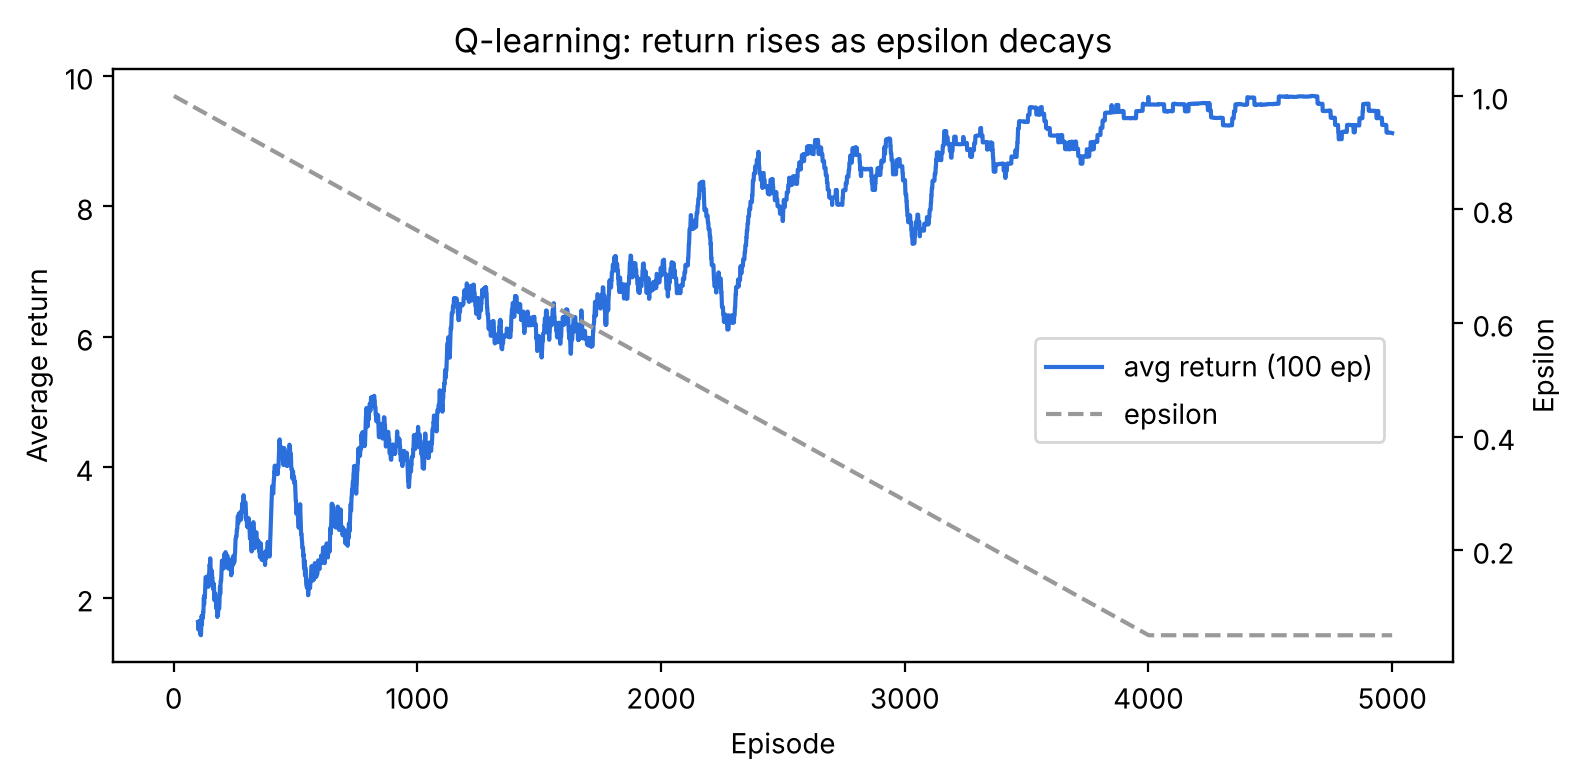

In [3]:
os.makedirs("logs", exist_ok=True)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(hist.Episode, hist.Return.rolling(100).mean(), color="#2a6fdb", label="avg return (100 ep)")
ax1.set_xlabel("Episode"); ax1.set_ylabel("Average return")
ax2 = ax1.twinx()
ax2.plot(hist.Episode, hist.Epsilon, color="#999999", linestyle="--", label="epsilon")
ax2.set_ylabel("Epsilon")
ax1.set_title("Q-learning: return rises as epsilon decays")
fig.legend(loc="center right", bbox_to_anchor=(0.88, 0.5))
fig.tight_layout()
fig.savefig("logs/learning_curve.png", dpi=120)
plt.show()

## The learned policy

The greedy policy picks the action with the highest Q-value in each cell.
`C` = charger, `T` = trap, `X` = obstacle.

In [4]:
policy = agent.policy(env)
print(policy_grid(policy, "LEARNED POLICY"))

q_table = pd.DataFrame([dict(State=str(s), **{a: agent.q[(s, a)] for a in MOVES}, Best=policy[s])
                        for s in sorted(policy)])
print("\nQ-TABLE")
display(q_table.style.hide(axis="index").format(precision=2))

LEARNED POLICY
   >   >   >   v
   v   X   v   v
   >   >   >   v
   ^   T   >   C

Q-TABLE


State,up,down,left,right,Best
"(0, 0)",4.35,4.23,4.31,4.80,right
"(0, 1)",4.99,5.00,4.40,5.61,right
"(0, 2)",5.69,6.19,5.26,6.46,right
"(0, 3)",6.18,7.22,5.86,6.43,down
"(1, 0)",4.15,4.17,4.12,4.15,down
"(1, 2)",5.91,7.46,6.59,7.16,down
"(1, 3)",6.56,7.97,6.84,7.27,down
"(2, 0)",4.36,4.20,4.38,4.41,right
"(2, 1)",4.43,0.30,4.29,5.30,right
"(2, 2)",6.69,7.63,5.92,8.43,right


## Episode with the learned policy

One run from the start, no exploration. Same path-log format as Lab 4.

In [5]:
def run_greedy_episode(policy, seed, max_steps=50):
    env = VacuumEnv(GRID, living_reward=LIVING_REWARD, seed=seed)
    state, total, log, path = env.reset(), 0.0, [], [START]
    for step in range(1, max_steps + 1):
        action = policy[state]
        nxt, reward, done, info = env.step(action)   # info only for the log
        total += reward
        log.append(dict(Step=step, From=state, Action=action, Actual=info["actual"], To=nxt,
                        Note=" ".join(n for n, hit in (("slipped", info["actual"] != action),
                                                      ("stopped", nxt == state)) if hit),
                        Reward=round(reward, 2), Total=round(total, 2)))
        state = nxt
        path.append(state)
        if done:
            break
    outcome = {"charger": "RECHARGED at the charger", "trap": "STUCK in the trap"}.get(
        outcome_of(state), f"never went home (stopped after {max_steps} steps)")
    print("PATH LOG")
    display(pd.DataFrame(log).style.hide(axis="index").format(precision=2))
    print(f"\nPath: {' -> '.join(map(str, path))}")
    print(f"Outcome: {outcome}   Steps: {len(log)}   Total reward: {total:.2f}")
    return dict(path=path, log=log, outcome=outcome, total=total)

greedy_run = run_greedy_episode(policy, seed=17)

PATH LOG


Step,From,Action,Actual,To,Note,Reward,Total
1,"(0, 0)",right,right,"(0, 1)",,-0.04,-0.04
2,"(0, 1)",right,up,"(0, 1)",slipped stopped,-0.04,-0.08
3,"(0, 1)",right,down,"(0, 1)",slipped stopped,-0.04,-0.12
4,"(0, 1)",right,right,"(0, 2)",,-0.04,-0.16
5,"(0, 2)",right,right,"(0, 3)",,-0.04,-0.20
6,"(0, 3)",down,down,"(1, 3)",,-0.04,-0.24
7,"(1, 3)",down,down,"(2, 3)",,-0.04,-0.28
8,"(2, 3)",down,down,"(3, 3)",,9.96,9.68



Path: (0, 0) -> (0, 1) -> (0, 1) -> (0, 1) -> (0, 2) -> (0, 3) -> (1, 3) -> (2, 3) -> (3, 3)
Outcome: RECHARGED at the charger   Steps: 8   Total reward: 9.68


## How good is the learned policy?

Two checks:
1. Run the greedy policy for 2000 episodes and compare its average **discounted** return with
   V*(start) from value iteration.
2. Compare the arrows with the value iteration policy. Value iteration needs T and R, so it is
   only used here as an answer key, never by the agent.

In [6]:
U, vi_policy = value_iteration_reference(LIVING_REWARD, GAMMA)
print(policy_grid(vi_policy, "VALUE ITERATION POLICY (answer key)"))

ev_learned = evaluate(policy, LIVING_REWARD)
ev_optimal = evaluate(vi_policy, LIVING_REWARD)
rows = []
for name, ev in (("Q-learning", ev_learned), ("Value iteration", ev_optimal)):
    n = sum(ev["outcomes"].values())
    rows.append(dict(Policy=name, Charger_pct=100 * ev["outcomes"]["charger"] / n,
                     Trap_pct=100 * ev["outcomes"]["trap"] / n, Avg_steps=ev["avg_steps"],
                     Avg_discounted_return=ev["avg_discounted"]))
print(f"\nV*(start) = {U[START]:.2f}")
display(pd.DataFrame(rows).style.hide(axis="index").format(precision=2))

match = [s for s in policy if policy[s] == vi_policy[s]]
print(f"Policy match: {len(match)}/{len(policy)} states")
print("Differences (learned, optimal):", {s: (policy[s], vi_policy[s]) for s in policy if policy[s] != vi_policy[s]})

VALUE ITERATION POLICY (answer key)
   >   >   v   v
   v   X   v   v
   >   >   >   v
   ^   T   >   C

V*(start) = 4.86


Policy,Charger_pct,Trap_pct,Avg_steps,Avg_discounted_return
Q-learning,98.95,1.05,7.59,4.78
Value iteration,98.85,1.15,7.41,4.87


Policy match: 12/13 states
Differences (learned, optimal): {(0, 2): ('right', 'down')}


## Choosing the hyperparameters

Each experiment changes one value and keeps the others at the chosen setting. Every value is
averaged over 5 seeds; *Match* is the share of the 13 decision cells that agree with value iteration.

In [7]:
def experiment(name, values, seeds=range(5)):
    rows = []
    for v in values:
        kw = dict(living_reward=LIVING_REWARD, gamma=GAMMA, alpha=ALPHA,
                  epsilon_start=EPSILON_START, epsilon_end=EPSILON_END)
        if name == "epsilon":
            kw["epsilon_start"] = kw["epsilon_end"] = v
        else:
            kw[name] = v
        U, vi_pol = value_iteration_reference(kw["living_reward"], kw["gamma"])
        charger = disc = match = 0.0
        for sd in seeds:
            a, e, _ = run_qlearning(seed=sd, **kw)
            p = a.policy(e)
            ev = evaluate(p, kw["living_reward"], gamma=kw["gamma"])
            charger += 100 * ev["outcomes"]["charger"] / 2000
            disc += ev["avg_discounted"]
            match += sum(p[s] == vi_pol[s] for s in p) / len(p)
        n = len(seeds)
        rows.append({name: v, "Charger_pct": charger / n, "Avg_disc_return": disc / n,
                     "V*(start)": U[START], "Match": match / n})
    return pd.DataFrame(rows)

for name, values in (("living_reward", [0.0, -0.04, -0.4, -1.0, -2.0]),
                     ("gamma", [0.5, 0.9, 0.99]),
                     ("alpha", [0.01, 0.1, 0.5, 0.9]),
                     ("epsilon", [0.05, 0.3, 1.0])):
    print(name.upper() + ("  (constant epsilon; chosen setting decays 1.0 -> 0.05)" if name == "epsilon" else ""))
    display(experiment(name, values).style.hide(axis="index").format(precision=2))

LIVING_REWARD


living_reward,Charger_pct,Avg_disc_return,V*(start),Match
0.00,99.31,5.02,5.07,0.91
-0.04,99.16,4.80,4.86,0.89
-0.40,98.60,2.86,2.93,0.94
-1.00,98.85,-0.40,-0.28,0.91
-2.00,97.63,-5.72,-5.61,0.95


GAMMA


gamma,Charger_pct,Avg_disc_return,V*(start),Match
0.50,98.30,0.09,0.09,0.89
0.90,99.16,4.80,4.86,0.89
0.99,100.00,9.04,9.05,0.92


ALPHA


alpha,Charger_pct,Avg_disc_return,V*(start),Match
0.01,99.62,4.71,4.86,0.80
0.10,99.16,4.80,4.86,0.89
0.50,100.00,4.70,4.86,0.77
0.90,100.00,4.48,4.86,0.65


EPSILON  (constant epsilon; chosen setting decays 1.0 -> 0.05)


epsilon,Charger_pct,Avg_disc_return,V*(start),Match
0.05,99.49,4.72,4.86,0.69
0.30,98.77,4.74,4.86,0.91
1.00,98.90,4.74,4.86,0.86


## When the living reward is too negative

The optimal policy at -2.0 changes: from (3, 0) the robot walks **into the trap** on purpose,
because ending at -1 is cheaper than paying -2 per step to go around.

In [8]:
for lr in (-0.04, -2.0):
    _, p = value_iteration_reference(lr, GAMMA)
    print(policy_grid(p, f"OPTIMAL POLICY, living reward {lr}"))
    print()

OPTIMAL POLICY, living reward -0.04
   >   >   v   v
   v   X   v   v
   >   >   >   v
   ^   T   >   C

OPTIMAL POLICY, living reward -2.0
   >   >   v   v
   v   X   v   v
   >   >   >   v
   >   T   >   C



## Saving the logs

In [9]:
q_table.to_csv("logs/lab5_q_table.csv", index=False)
hist.to_csv("logs/lab5_learning_curve.csv", index=False)
with open("logs/lab5_policy.txt", "w") as f:
    f.write(policy_grid(policy, "LEARNED POLICY") + "\n")

df = pd.DataFrame(greedy_run["log"])
df["From"], df["To"] = df["From"].astype(str), df["To"].astype(str)
df["Outcome"] = ""
df.loc[df.index[-1], "Outcome"] = greedy_run["outcome"]
df.to_csv("logs/lab5_log_greedy_episode.csv", index=False)
for f in ("lab5_q_table.csv", "lab5_learning_curve.csv", "lab5_policy.txt",
          "lab5_log_greedy_episode.csv", "learning_curve.png"):
    print("saved logs/" + f)

saved logs/lab5_q_table.csv
saved logs/lab5_learning_curve.csv
saved logs/lab5_policy.txt
saved logs/lab5_log_greedy_episode.csv
saved logs/learning_curve.png


## Results and discussion

- **The robot learned to recharge without knowing T or R.** After 5000 episodes the greedy policy reaches the charger in about 99% of runs. Lab 4's random robot managed 27%.
- **It is close to optimal.** The average discounted return is 4.78 against V*(start) = 4.86 from value iteration. The learned arrows match the answer key in 12 of 13 cells. The one difference, (0, 2), is a near-tie between right and down.
- **Why ~1% still end in the trap.** The best path passes (2, 1) and (2, 2), where a 10% slip down lands in the trap. No policy can avoid that risk entirely; value iteration has the same trap rate.
- **Living reward -0.04:** small enough to keep a safe route. At -2.0 even the optimal robot jumps into the trap from (3, 0).
- **Gamma 0.9:** keeps the +10 charger worth chasing from six steps away (0.9⁶ ≈ 0.53). At 0.5 it is worth almost nothing that far out.
- **Alpha 0.1:** slips make each sample noisy, so averaging slowly works best. 0.5 and 0.9 chase the last sample and match the answer key much less often. 0.01 is too slow to finish learning.
- **Epsilon 1.0 → 0.05:** explore while knowing nothing, then exploit. A constant 0.05 stops exploring too early and has the worst policy match. A constant 0.3 matches about as well, but it keeps taking random moves forever; decaying ends training almost greedy (97.6% charger in the last 500 episodes).